(19968, 81)

,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,NO2,O3,PM10,...,pct_ouvriers,pct_retraites,pct_sans_activite,pct_agriculteurs,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,sos_present
0,2021-S01,01,0.326250,0.610000,0.0500,0.4225,0.002025,16.272727,20.909091,19.363636,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
1,2021-S02,01,0.491563,1.065833,0.1375,3.0825,0.005350,22.257143,27.214286,13.928571,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
2,2021-S03,01,0.581875,0.396667,0.0800,5.8525,0.008425,14.635714,50.714286,8.214286,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
3,2021-S04,01,0.399687,0.385833,0.0900,3.4125,0.006250,21.864286,34.071429,11.428571,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
4,2021-S05,01,0.390000,0.360833,0.0850,1.2350,0.004900,21.028571,30.428571,15.714286,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False


DatetimeIndex(['2021-01-04', '2021-01-11', '2021-01-18', '2021-01-25',
               '2021-02-01', '2021-02-08', '2021-02-15', '2021-02-22',
               '2021-03-01', '2021-03-08',
               ...
               '2024-10-21', '2024-10-28', '2024-11-04', '2024-11-11',
               '2024-11-18', '2024-11-25', '2024-12-02', '2024-12-09',
               '2024-12-16', '2024-12-23'],
              dtype='datetime64[us]', name='date_semaine', length=208, freq='W-MON')


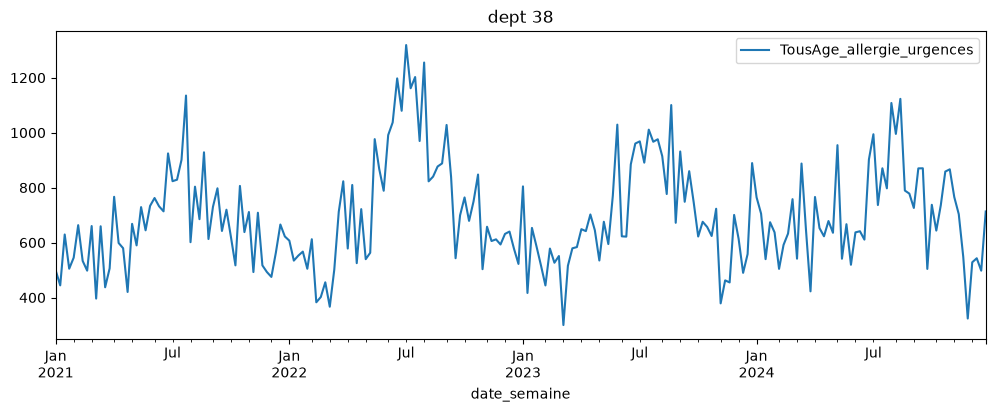

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df=pd.read_csv('../data/final_metropole/Merge_final_2.csv',dtype={"code_dept": str})

display(df.shape)
display(df.head())

s38 = df.loc[df["code_dept"] == "38"]
dates = pd.to_datetime(s38["date_semaine"] + "-1", format="%G-S%V-%u")
s38 = s38.set_index(dates)[["TousAge_allergie_urgences"]]
s38 = s38.asfreq('W-MON')     
print(s38.index)

s38.plot(figsize=(12, 4));   
plt.title("dept 38");

In [20]:
annee = s38.index.year
train = s38[annee <= 2022]
val   = s38[annee == 2023]
test  = s38[annee == 2024]
print(len(train), len(val), len(test)) 


104 52 52


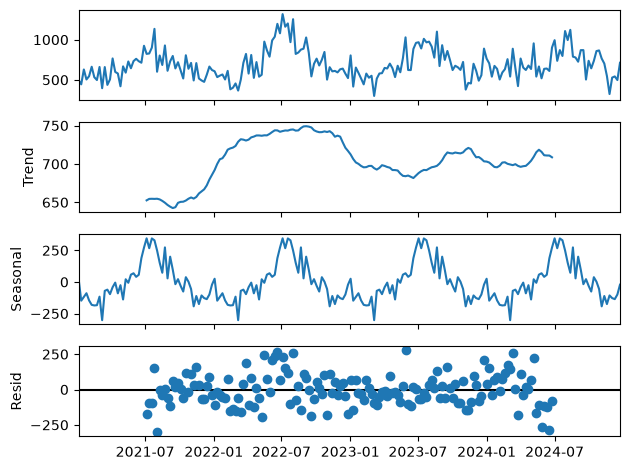

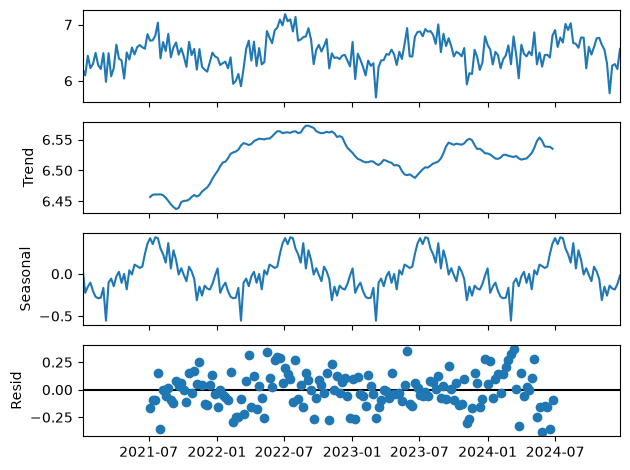

In [21]:
from statsmodels.tsa.seasonal import seasonal_decompose

res = seasonal_decompose(s38)
res.plot()
plt.show()

res = seasonal_decompose(np.log(s38))
res.plot()
plt.show()

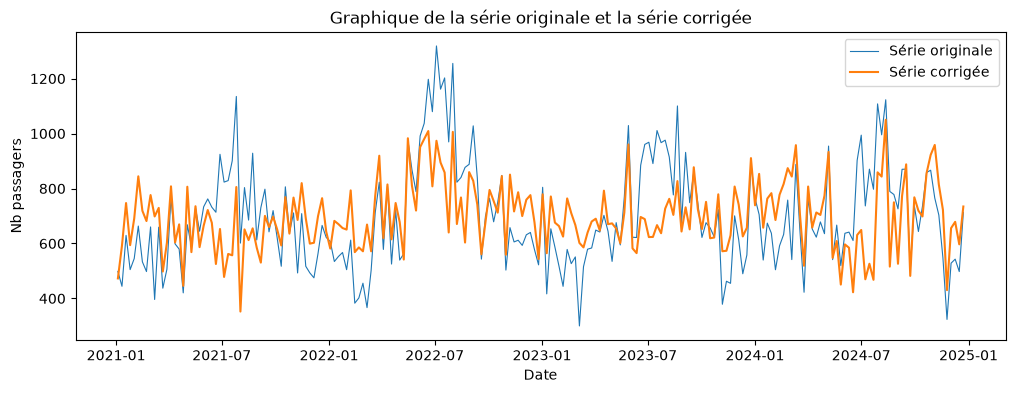

In [22]:
mult = seasonal_decompose(s38)

cvs = s38['TousAge_allergie_urgences'] - mult.seasonal

plt.figure(figsize=(12, 4))
plt.plot(s38, label='Série originale', linewidth=0.8)
plt.plot(cvs, label='Série corrigée')
plt.title('Graphique de la série originale et la série corrigée')
plt.xlabel('Date')
plt.ylabel('Nb passagers')
plt.legend()
plt.show();

brute               0.0818
diff(1)             0.0000
diff(52)            0.4314
diff(1)+diff(52)    0.0000
Name: p ADF, dtype: float64


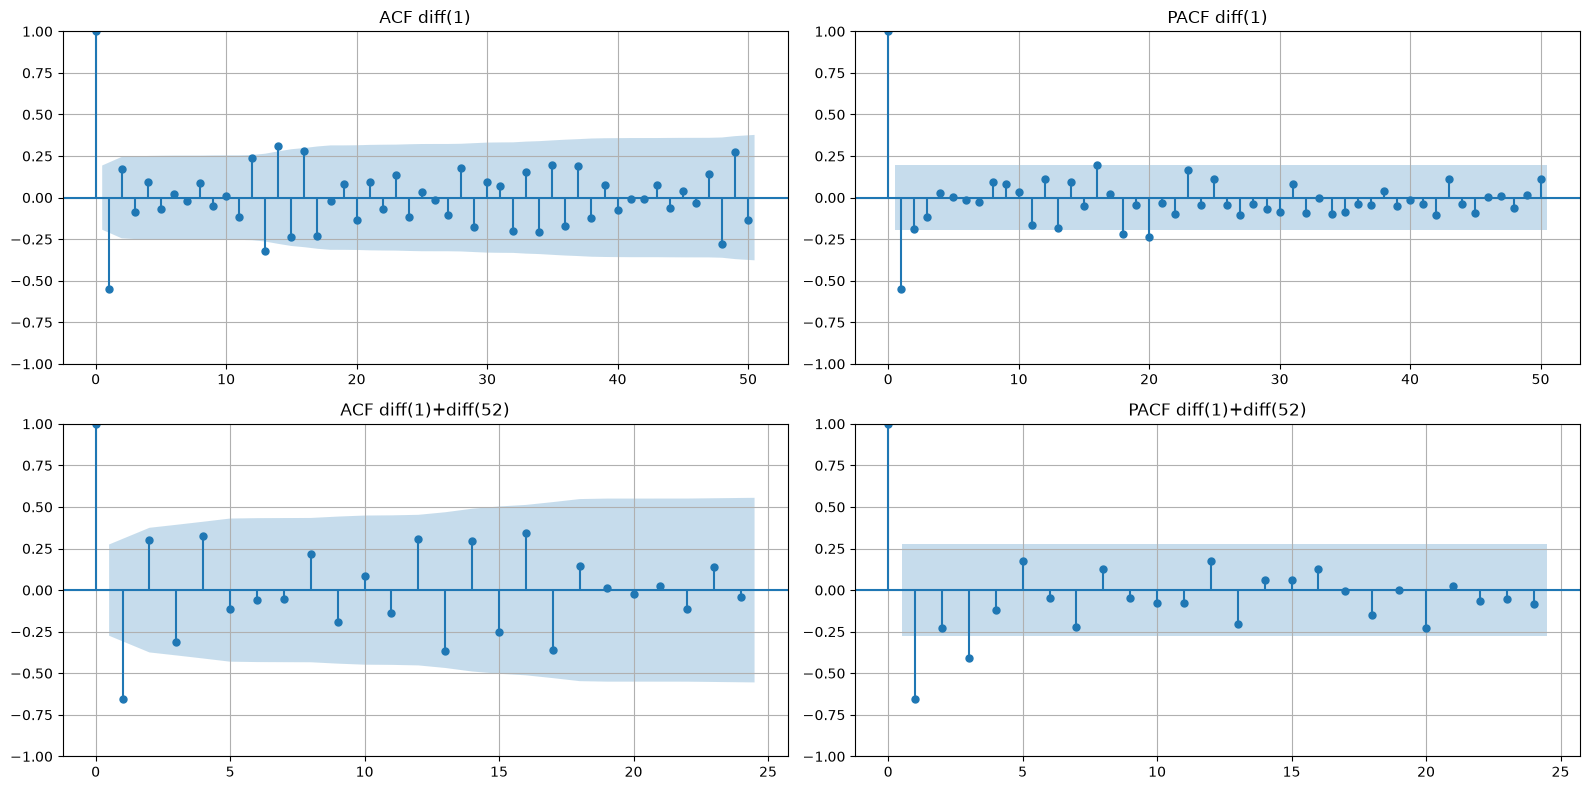

In [23]:
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

S = 52
y = s38["TousAge_allergie_urgences"].asfreq("W-MON")   
y_train = y[y.index.year <= 2022]

transfos = {
    "brute":           y_train,
    "diff(1)":         y_train.diff(1),
    "diff(52)":        y_train.diff(S),
    "diff(1)+diff(52)": y_train.diff(1).diff(S),
}
print(pd.Series({k: adfuller(v.dropna())[1] for k, v in transfos.items()}, name="p ADF").round(4))

fig, axes = plt.subplots(2, 2, figsize=(16, 8))
for row, (nom, serie) in enumerate([("diff(1)", y_train.diff(1)),
                                    ("diff(1)+diff(52)", y_train.diff(1).diff(S))]):
    s = serie.dropna()
    nlags = min(50, len(s) // 2 - 1)
    plot_acf(s, lags=nlags, ax=axes[row, 0], title=f"ACF {nom}")
    plot_pacf(s, lags=nlags, ax=axes[row, 1], title=f"PACF {nom}", method="ywm")
    for ax in axes[row]:
        ax.grid()
plt.tight_layout()
plt.show()

#### _diff(1)_
#### p<0.0001 et ACF avec un seul pic net au retard 1 (−0,55) => q=1
#### PACF décroît progressivement en restant négative. => p=0
#### _diff(1)+diff(52)_
#### p<0.0001 et ACF avec un pic au retard 1 renforcé (−0,66) => q=1 
#### deux pics significatifs en PACF, aux retards 1 et 3. => p =1,2,3? 
#### Notons un possible excès de différenciation _dès diff(1), et plus encore après diff(52)_, 
#### avec une estimation fragile sur seulement 51 points => D=0 & d=0,1?


In [24]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

y_val  = y[y.index.year == 2023]
y_test = y[y.index.year == 2024]

def one_step(order, sorder=(0, 0, 0, 0), fit_last_year=2022, eval_year=2023):
    """Estime le modèle sur les années y_train
    Renvoie le modèle ajusté et les prévisions à t+1 pour chaque semaine de y_eval"""
    trend = "c" if (order[1] == 0 and sorder[1] == 0) else "n"
    fit_m  = y.index.year <= fit_last_year
    hist_m = y.index.year <= eval_year
    res = SARIMAX(y[fit_m], order=order, seasonal_order=sorder,
                  trend=trend).fit(disp=False, maxiter=200)
    res_ext = res.apply(y[hist_m])                # mêmes paramètres, série prolongée
    start = y.index[y.index.year == eval_year][0]
    pred = res_ext.get_prediction(start=start)    # prévision à un pas (observations jusqu'à t-1)
    return res, pred

def scores(y_true, y_pred):
    m = y_true.notna() & y_pred.notna()
    return {"R2":   r2_score(y_true[m], y_pred[m]),
            "MAE":  mean_absolute_error(y_true[m], y_pred[m]),
            "RMSE": root_mean_squared_error(y_true[m], y_pred[m])}

In [25]:
import itertools, warnings
warnings.filterwarnings("ignore")   # SARIMAX émet beaucoup d'avertissements de convergence

results = []
for d, p, q, P, Q in itertools.product([0, 1], [0, 1], [0, 1], [0, 1], [0, 1]):
    order, sorder = (p, d, q), (P, 0, Q, 52)          # D = 0
    res, pred = one_step(order, sorder)               # ajustement 2021-2022, prévisions t+1 sur 2023
    m = scores(y_val, pred.predicted_mean)            # scores sur 2023
    results.append([order, sorder, res.bic, m["R2"], m["MAE"], m["RMSE"]])

grid = pd.DataFrame(results, columns=["order", "sorder", "BIC", "R2", "MAE", "RMSE"])
grid = grid.sort_values("RMSE").reset_index(drop=True)   # classement des modèles sur RMSE
display(grid.head(10).round(3))

,order,sorder,BIC,R2,MAE,RMSE
0,"(1, 0, 1)","(1, 0, 1, 52)",1347.891,0.401,112.236,142.134
1,"(1, 0, 1)","(0, 0, 0, 52)",1338.683,0.395,112.430,142.790
2,"(1, 0, 1)","(1, 0, 0, 52)",1343.277,0.390,112.806,143.387
3,"(1, 0, 1)","(0, 0, 1, 52)",1343.278,0.390,112.818,143.415
4,"(0, 0, 0)","(1, 0, 0, 52)",1401.244,0.380,115.062,144.617
5,"(1, 1, 1)","(0, 0, 0, 52)",1320.925,0.377,112.899,144.955
6,"(1, 1, 1)","(1, 0, 0, 52)",1325.558,0.376,112.913,145.055
7,"(1, 1, 1)","(0, 0, 1, 52)",1325.558,0.376,112.914,145.057
8,"(1, 1, 1)","(1, 0, 1, 52)",1330.193,0.376,112.916,145.060
9,"(0, 1, 1)","(0, 0, 0, 52)",1319.864,0.372,115.206,145.586


#### _Grille SARIMA (32 modèles, ajustement 2021-2022, prévision t+1 sur 2023)_
#### Meilleurs modèles : d = 0 => excès de différenciation confirmé
#### Termes saisonniers (s = 52) inutiles : (1,0,1)(0,0,0,52) ≈ (1,0,1)(1,0,1,52) en RMSE (142,8 vs 142,1),
#### avec un meilleur BIC => (1,0,1)(0,0,0,52) retenu

#### Écarts très faibles entre les 10 premiers modèles (RMSE 142-145)
#### => en dehors de diff(1), les choix importent peu


Modèle retenu : (1, 0, 1) (0, 0, 0, 0)
                                   SARIMAX Results                                   
Dep. Variable:     TousAge_allergie_urgences   No. Observations:                  104
Model:                      SARIMAX(1, 0, 1)   Log Likelihood                -660.053
Date:                       Tue, 03 Nov 2026   AIC                           1328.105
Time:                               07:49:24   BIC                           1338.683
Sample:                           01-04-2021   HQIC                          1332.390
                                - 12-26-2022                                         
Covariance Type:                         opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept     47.1261     30.782      1.531      0.126     -13.205     107.457
ar.L1          0.9293      0.043    

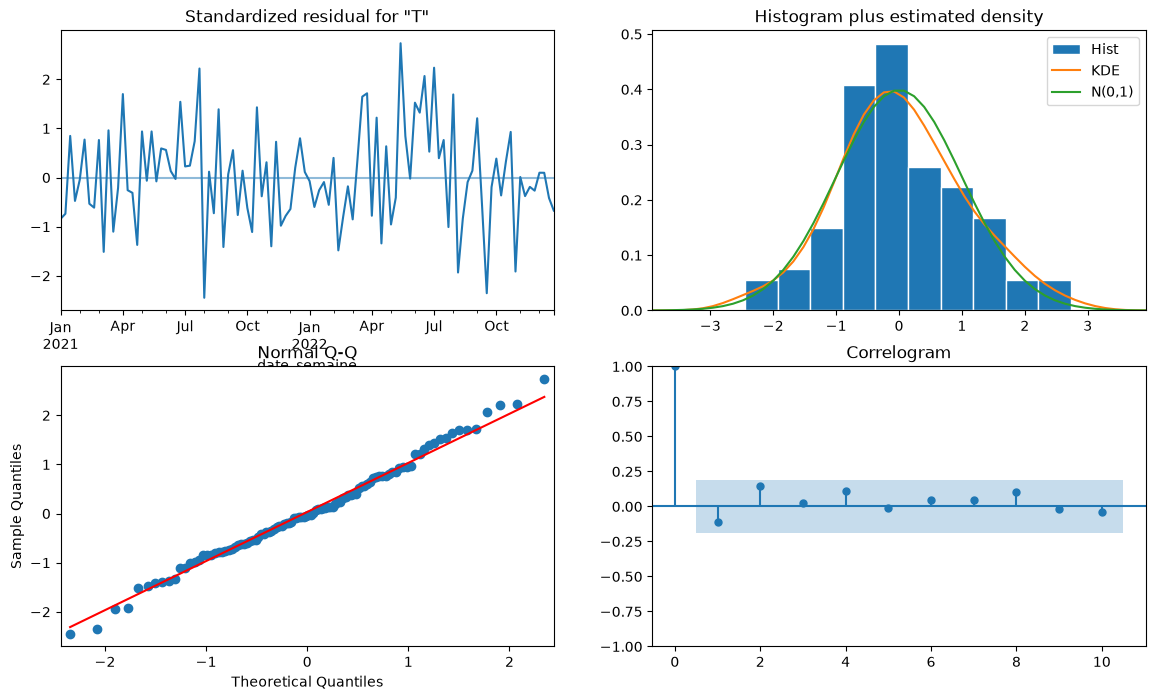

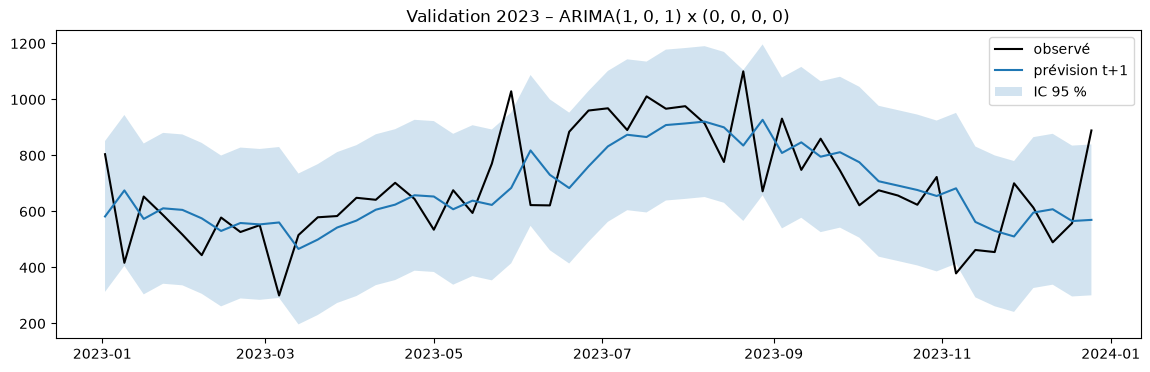

In [26]:
# meilleur modèle = plus petit BIC
best = proches.loc[proches["BIC"].idxmin()]
order, sorder = best["order"], best["sorder"]
if sorder[:3] == (0, 0, 0):          # aucun terme saisonnier
    sorder = (0, 0, 0, 0)
print("Modèle retenu :", order, sorder)

# Réajustement du modèle retenu sur 2021-2022 et prévisions t+1 sur 2023
res_best, pred_val = one_step(order, sorder)
print(res_best.summary())         

# Diagnostics des résidus : série, histogramme, QQ-plot, ACF
res_best.plot_diagnostics(figsize=(14, 8))
plt.show()

# Prévisions t+1 sur 2023 face aux observations
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(y_val, "k", label="observé")
ax.plot(pred_val.predicted_mean, label="prévision t+1")
ci = pred_val.conf_int()
ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], alpha=0.2, label="IC 95 %")
ax.set_title(f"Validation 2023 – ARIMA{order} x {sorder}")
ax.legend()
plt.show()

Colonnes constantes retirées : ['pression_mer']


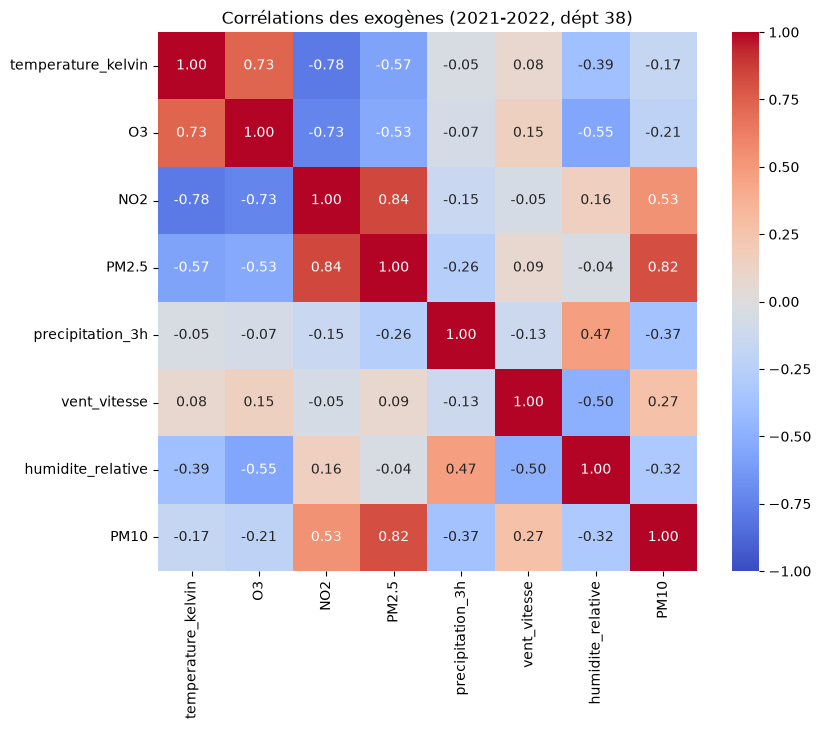

Variables proposées : ['temperature_kelvin', 'O3', 'NO2', 'precipitation_3h', 'vent_vitesse', 'humidite_relative', 'PM10']


In [27]:
import seaborn as sns

# Variables testées par ordre de priorité : en cas de corrélation forte, la première est gardée
candidats = ["temperature_kelvin", "O3", "NO2", "PM2.5", "precipitation_3h",
             "vent_vitesse", "humidite_relative", "PM10", "pression_mer"]

# Table du département 38, indexée comme y 
d38 = df[df["code_dept"] == "38"].copy()
d38.index = pd.to_datetime(d38["date_semaine"] + "-1", format="%G-S%V-%u")
X = d38[candidats].asfreq("W-MON").astype(float)

# Décalage d'une semaine : y(t) n'est prédit qu'avec les exogènes connues à t-1
X = X.shift(1).iloc[1:]   # la première semaine, sans valeur précédente, est retirée

# Retrait des colonnes constantes sur l'entraînement (écart-type nul => standardisation impossible)
train_m = X.index.year <= 2022
constantes = X.columns[X[train_m].std() == 0].tolist()
print("Colonnes constantes retirées :", constantes)
X = X.drop(columns=constantes)

# Standardisation avec les statistiques d'entraînement (2021-2022) uniquement
X = (X - X[train_m].mean()) / X[train_m].std()

# Corrélations sur l'entraînement, en heatmap annotée
corr = X[train_m].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Corrélations des exogènes (2021-2022, dépt 38)")
plt.show()

# Variable écartée si |r| > 0,8 avec une variable déjà retenue
retenues = []
for c in X.columns:
    if all(abs(corr.loc[c, r]) <= 0.8 for r in retenues):
        retenues.append(c)
print("Variables proposées :", retenues)

In [28]:
import itertools
from statsmodels.tsa.statespace.sarimax import SARIMAX

yx = y.loc[X.index]   # cible alignée sur X 

def one_step_x(order, cols, fit_last_year=2022, eval_year=2023):
    """Comme one_step, avec les colonnes cols de X en exogènes """
    exog = X[list(cols)] if cols else None
    trend = "c" if order[1] == 0 else "n"
    fit_m, hist_m = yx.index.year <= fit_last_year, yx.index.year <= eval_year
    res = SARIMAX(yx[fit_m], exog=None if exog is None else exog[fit_m],
                  order=order, trend=trend).fit(disp=False, maxiter=200)
    res_ext = res.apply(yx[hist_m], exog=None if exog is None else exog[hist_m])
    start = yx.index[yx.index.year == eval_year][0]
    return res, res_ext.get_prediction(start=start)

results = []
for k in range(0, 7):                                   # de 0 à 6 variables exogènes
    for cols in itertools.combinations(retenues, k):
        res, pred = one_step_x(order, cols)             # order = SARIMA retenu plus haut
        m = scores(y_val, pred.predicted_mean)
        results.append([cols, k, res.bic, m["R2"], m["MAE"], m["RMSE"]])

gridx = pd.DataFrame(results, columns=["exog", "k", "BIC", "R2", "MAE", "RMSE"])
gridx = gridx.sort_values("RMSE").reset_index(drop=True)
display(gridx.head(15).round(3))

,exog,k,BIC,R2,MAE,RMSE
0,"(temperature_kelvin, precipitation_3h)",2,1317.571,0.489,105.987,131.310
1,"(temperature_kelvin, precipitation_3h, vent_vi...",4,1330.591,0.487,107.735,131.521
2,"(temperature_kelvin, O3, precipitation_3h, ven...",5,1335.164,0.487,107.779,131.534
3,"(temperature_kelvin, precipitation_3h, vent_vi...",4,1330.503,0.486,107.804,131.685
4,"(temperature_kelvin, precipitation_3h, vent_vi...",5,1335.098,0.485,108.130,131.765
5,"(temperature_kelvin, O3, precipitation_3h, ven...",4,1330.251,0.485,107.978,131.788
6,"(temperature_kelvin, O3, precipitation_3h, PM10)",4,1326.036,0.485,107.778,131.796
7,"(temperature_kelvin, NO2, precipitation_3h, hu...",5,1333.186,0.484,108.423,131.901
8,"(temperature_kelvin, O3, precipitation_3h, ven...",6,1335.623,0.482,107.971,132.207
9,"(temperature_kelvin, precipitation_3h, humidit...",4,1330.320,0.482,108.389,132.216


Exogènes retenues : ['temperature_kelvin', 'precipitation_3h']
                                   SARIMAX Results                                   
Dep. Variable:     TousAge_allergie_urgences   No. Observations:                  103
Model:                      SARIMAX(1, 0, 1)   Log Likelihood                -644.881
Date:                       Tue, 03 Nov 2026   AIC                           1301.763
Time:                               07:58:28   BIC                           1317.571
Sample:                           01-11-2021   HQIC                          1308.166
                                - 12-26-2022                                         
Covariance Type:                         opg                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
intercept            138.4467     98.429      1.407      0.160     -54.470 

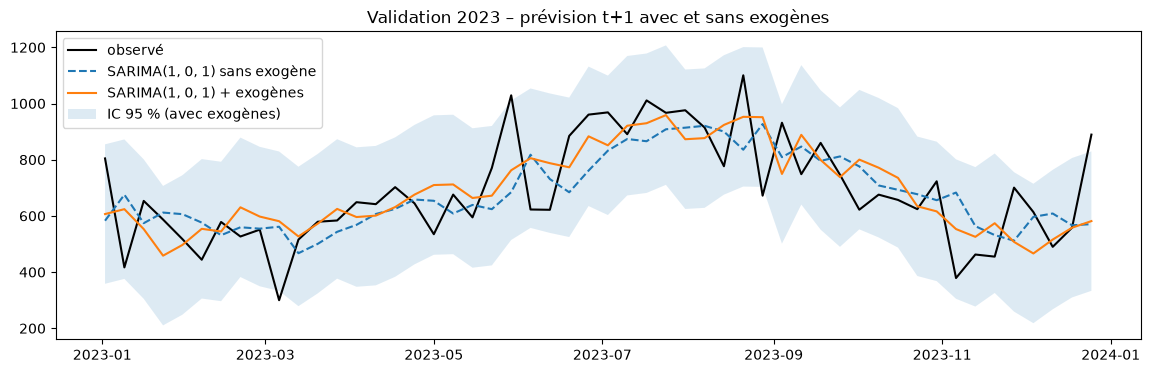

In [33]:
# Meilleur modèle exogène : parmi ceux à moins de 1 % du meilleur RMSE, le plus petit BIC
proches_x = gridx[gridx["RMSE"] <= 1.01 * gridx["RMSE"].min()]
best_x = proches_x.loc[proches_x["BIC"].idxmin()]
cols_x = list(best_x["exog"])
print("Exogènes retenues :", cols_x)

# Modèle avec exogènes et modèle de référence sans exogène, sur les mêmes semaines
res_x, pred_x = one_step_x(order, cols_x)
res_0, pred_0 = one_step_x(order, [])
print(res_x.summary())

# Comparaison graphique sur 2023
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(y_val, "k", label="observé")
ax.plot(pred_0.predicted_mean, "--", label=f"SARIMA{order} sans exogène")
ax.plot(pred_x.predicted_mean, label=f"SARIMA{order} + exogènes")
ci = pred_x.conf_int()
ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], alpha=0.15, label="IC 95 % (avec exogènes)")
ax.set_title("Validation 2023 – prévision t+1 avec et sans exogènes")
ax.legend()
plt.show()

#### statsmodels ne propose pas de SARIMA « emboîté » (un modèle unique avec le département comme niveau) 
#### Je fais donc tourner une modélisation par département, avec les hyperparamètres choisis sur le 38, en testant 4 modèles :
#### sans exo, température, précipitations_3h, température ET précipitations_3h.

In [42]:
import warnings
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tools.sm_exceptions import ConvergenceWarning
warnings.simplefilter("ignore", ConvergenceWarning)    

# --- Paramètres ---
CIBLE  = "TousAge_allergie_urgences"
TEMP   = "temperature_kelvin"
PRECIP = "precipitation_3h"
MODELES = {
    "sans_exo":    [],
    "temp":        [TEMP],
    "precip":      [PRECIP],
    "temp+precip": [TEMP, PRECIP],
}

def prepare(dept):
    """Cible y et exogènes X d'un département, indexées par le lundi de chaque semaine ISO."""
    d = df.loc[df["code_dept"] == dept].copy()
    d.index = pd.to_datetime(d["date_semaine"] + "-1", format="%G-S%V-%u")
    d = d[~d.index.duplicated()].sort_index().asfreq("W-MON")
    return d[CIBLE], d[[TEMP, PRECIP]].interpolate(limit_direction="both")   # pas de NaN en exogène

def fit_predict(y, X, cols, fit_last_year=2022, eval_year=2023):
    """Ajustement jusqu'à fit_last_year, prévision t+1 sur eval_year, avec l'order retenu sur le 38."""
    exog = X[cols] if cols else None
    trend = "c" if order[1] == 0 else "n"
    fit_m, hist_m = y.index.year <= fit_last_year, y.index.year <= eval_year
    res = SARIMAX(y[fit_m], exog=None if exog is None else exog[fit_m],
                  order=order, trend=trend).fit(disp=False, maxiter=200)
    res_ext = res.apply(y[hist_m], exog=None if exog is None else exog[hist_m])
    start = y.index[y.index.year == eval_year][0]
    return res, res_ext.get_prediction(start=start).predicted_mean

# --- Boucle sur tous les départements et les 4 modèles ---
resultats, preds = [], []
for dept in sorted(df["code_dept"].unique()):
    y_d, X_d = prepare(dept)
    y_v = y_d[y_d.index.year == 2023]                   # valeurs observées en 2023
    texte = f"Dépt {dept}"
    for nom, cols in MODELES.items():
        try:
            res, pred = fit_predict(y_d, X_d, cols)
            pred = pred.reindex(y_v.index)
            ok = y_v.notna() & pred.notna()             # semaines observées et prévues
            m = scores(y_v[ok], pred[ok])
        except Exception as e:                          # un échec ne bloque pas la boucle
            texte += f" | {nom}: échec ({e})"
            continue
        resultats.append([dept, nom, m["R2"], m["MAE"], m["RMSE"]])
        preds.append(pd.DataFrame({"dept": dept, "modele": nom, "y": y_v[ok], "pred": pred[ok]}))
        texte += f" | {nom}: R²={m['R2']:.3f}"
    print(texte)

res_dept = pd.DataFrame(resultats, columns=["dept", "modele", "R2", "MAE", "RMSE"])

# --- Estimation globale des modèles ---
P = pd.concat(preds)
lignes_glob = []
for nom in MODELES:
    P_mod = P[P["modele"] == nom]
    m = scores(P_mod["y"], P_mod["pred"])
    lignes_glob.append([nom, m["R2"], m["MAE"], m["RMSE"]])
display(pd.DataFrame(lignes_glob, columns=["modele", "R2", "MAE", "RMSE"]).round(3))

Dépt 01 | sans_exo: R²=0.305 | temp: R²=-0.019 | precip: R²=0.301 | temp+precip: R²=0.286
Dépt 02 | sans_exo: R²=0.109 | temp: R²=0.004 | precip: R²=0.069 | temp+precip: R²=-0.843
Dépt 03 | sans_exo: R²=0.283 | temp: R²=0.333 | precip: R²=0.335 | temp+precip: R²=0.328
Dépt 04 | sans_exo: R²=0.251 | temp: R²=0.307 | precip: R²=0.238 | temp+precip: R²=0.279
Dépt 05 | sans_exo: R²=0.112 | temp: R²=0.210 | precip: R²=0.035 | temp+precip: R²=0.180
Dépt 06 | sans_exo: R²=0.157 | temp: R²=0.212 | precip: R²=0.060 | temp+precip: R²=0.182
Dépt 07 | sans_exo: R²=0.172 | temp: R²=0.315 | precip: R²=0.161 | temp+precip: R²=0.305
Dépt 08 | sans_exo: R²=0.078 | temp: R²=0.206 | precip: R²=0.035 | temp+precip: R²=0.160
Dépt 09 | sans_exo: R²=0.055 | temp: R²=0.276 | precip: R²=0.026 | temp+precip: R²=0.228
Dépt 10 | sans_exo: R²=0.120 | temp: R²=0.130 | precip: R²=0.135 | temp+precip: R²=0.130
Dépt 11 | sans_exo: R²=0.219 | temp: R²=0.367 | precip: R²=0.172 | temp+precip: R²=0.364
Dépt 12 | sans_exo:

,modele,R2,MAE,RMSE
0,sans_exo,0.410,179.230,248.472
1,temp,0.461,171.966,237.428
2,precip,0.414,179.339,247.524
3,temp+precip,0.446,174.471,240.606
